<a href="https://colab.research.google.com/github/Viswas-Vinayakumar/AI-search/blob/main/Vectorization_demo_Meaningmap.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!python -m spacy download de_core_news_md -q
import numpy as np
import spacy
import matplotlib.pyplot as plt

nlp = spacy.load("de_core_news_md")      # German model: every word → 300 numbers

def cos(a, b):                           # cosine similarity: 1 = same direction, 0 = unrelated
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.4/44.4 MB 20.3 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('de_core_news_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [4]:
v = nlp("Streit")[0].vector
print("how many numbers:", len(v))
print("first 5 numbers: ", np.round(v[:5], 2))

how many numbers: 300
first 5 numbers:  [-0.03  3.8   3.23  1.08 -2.22]


In [5]:
pairs = [("Streit", "Konflikt"), ("Streit", "Mediation"), ("Streit", "Excel"),
         ("Stress", "Burnout"), ("Stress", "Excel")]
for a, b in pairs:
    print(f"{a:<8} vs {b:<10} similarity {cos(nlp(a)[0].vector, nlp(b)[0].vector):.2f}")

Streit   vs Konflikt   similarity 0.74
Streit   vs Mediation  similarity 0.29
Streit   vs Excel      similarity -0.09
Stress   vs Burnout    similarity 0.60
Stress   vs Excel      similarity 0.11


In [6]:
words = ["Streit", "Team", "schlichten"]
vecs = [nlp(w)[0].vector for w in words]
for w, x in zip(words, vecs):
    print(f"{w:<11} first 3 numbers: {np.round(x[:3], 2)}")
by_hand = (vecs[0] + vecs[1] + vecs[2]) / 3
print("average      first 3 numbers:", np.round(by_hand[:3], 2))
print("same as np.mean?", np.allclose(by_hand, np.mean(vecs, axis=0)))

Streit      first 3 numbers: [-0.03  3.8   3.23]
Team        first 3 numbers: [-5.8   4.13  4.5 ]
schlichten  first 3 numbers: [ 1.97 -0.03 -1.81]
average      first 3 numbers: [-1.29  2.63  1.97]
same as np.mean? True


In [7]:
length = np.sqrt(np.sum(by_hand ** 2))
unit = by_hand / length
print(f"length before: {length:.2f}  ->  length after: {np.sqrt(np.sum(unit ** 2)):.2f}")

length before: 30.09  ->  length after: 1.00


In [8]:
def embed(text):
    vs = [t.vector for t in nlp(text) if t.is_alpha and not t.is_stop and t.has_vector]
    m = np.mean(vs, axis=0)          # step 3: average
    return m / np.linalg.norm(m)     # step 4: normalise

coaches = {
    "Konfliktcoach": "Spannungen im Team lösen, Mediation, schwierige Gespräche",
    "Scrum-Trainer": "Scrum und Kanban für Softwareteams einführen",
    "Stresscoach":   "Burnout vorbeugen und mit Druck bei der Arbeit umgehen",
}
query = "Streit im Team schlichten"
q = embed(query)
for name, s in sorted(((n, float(embed(t) @ q)) for n, t in coaches.items()), key=lambda x: -x[1]):
    print(f"   {s:.2f}  {name}")

   0.76  Konfliktcoach
   0.44  Stresscoach
   0.26  Scrum-Trainer


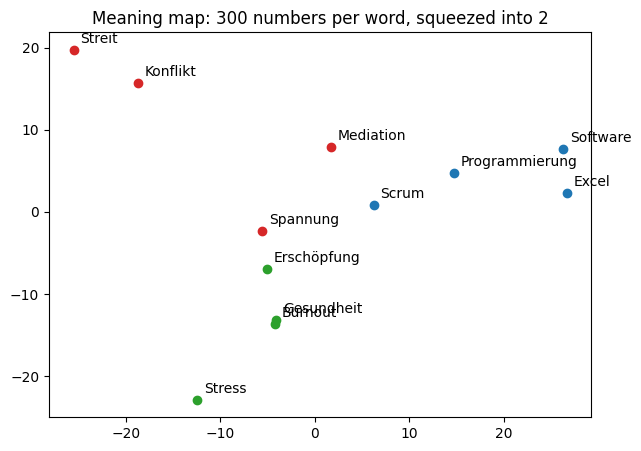

In [9]:
words = ["Streit", "Konflikt", "Mediation", "Spannung",
         "Scrum", "Software", "Programmierung", "Excel",
         "Stress", "Burnout", "Erschöpfung", "Gesundheit"]
M = np.array([nlp(w)[0].vector for w in words])
M = M - M.mean(axis=0)
_, _, vt = np.linalg.svd(M, full_matrices=False)
xy = M @ vt[:2].T                       # keep the 2 most important directions
plt.figure(figsize=(7, 5))
colors = ["tab:red"] * 4 + ["tab:blue"] * 4 + ["tab:green"] * 4
for (x, y), w, c in zip(xy, words, colors):
    plt.scatter(x, y, color=c)
    plt.annotate(w, (x, y), textcoords="offset points", xytext=(5, 5))
plt.title("Meaning map: 300 numbers per word, squeezed into 2")
plt.show()